# Mississippi Senate special: the vote count, batch by batch

Just for fun; not part of the forecast. Colom (D) vs. Hyde-Smith (R), from the batch table
scraped at 2026-11-06 19:00 PST (`ms-special-20261106-1900pst.csv`). `ms_special_batches.py`
does the parsing.

- Margins are signed **Colom (D) positive** throughout.
- Each batch's Colom and Hyde-Smith votes are derived from its total and margin, with
  `OTHER_SHARE` of the batch assumed to go to other candidates (0 = treat as two-way; see the
  script's docstring). Margins are exact either way.
- Times are only to the hour ("5h ago"), and the 121 election-night batches are labelled just
  "Nov. 3", so the charts put **votes counted** on the x-axis instead of time.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from ms_special_batches import OTHER_SHARE, load_batches

SNAPSHOT_CSV = "ms-special-20261106-1900pst.csv"

DEM_COLOR, GOP_COLOR = "#2a78d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4df"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
})

thousands = mticker.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k")
signed_votes = mticker.FuncFormatter(lambda x, _: f"D+{x:,.0f}" if x > 0 else f"R+{-x:,.0f}" if x < 0 else "0")
signed_pct = mticker.FuncFormatter(lambda x, _: f"D+{x:.0f}" if x > 0 else f"R+{-x:.0f}" if x < 0 else "0")


def fmt_margin(m, pct=False):
    if m == 0:
        return "Even"
    s = f"{abs(m):.2f} pts" if pct else f"{abs(m):,.0f}"
    return f"Colom +{s}" if m > 0 else f"Hyde-Smith +{s}"


batches = load_batches(SNAPSHOT_CSV)
print(f"OTHER_SHARE = {OTHER_SHARE}")
batches.tail()

OTHER_SHARE = 0.0


,batch,last_updated,hours_ago,approx_time_pst,new_votes,batch_margin,other_votes,dem_votes,gop_votes,dem_pct,...,cumulative_votes,cumulative_dem_votes,cumulative_gop_votes,cumulative_other_votes,cumulative_dem_pct,cumulative_gop_pct,racewide_margin,racewide_margin_pct,est_pct_in,unexplained_shift
199,200,6h ago,6.0,2026-11-06 13:00:00,220,100,0.0,160.0,60.0,72.727273,...,952512,477320.5,475191.5,0.0,50.111757,49.888243,2129,0.223514,97.0,0
200,201,5h ago,5.0,2026-11-06 14:00:00,63,0,0.0,31.5,31.5,50.000000,...,952575,477352.0,475223.0,0.0,50.111750,49.888250,2129,0.223499,97.0,0
201,202,5h ago,5.0,2026-11-06 14:00:00,615,364,0.0,489.5,125.5,79.593496,...,953190,477841.5,475348.5,0.0,50.130771,49.869229,2493,0.261543,97.0,0
202,203,5h ago,5.0,2026-11-06 14:00:00,32,5,0.0,18.5,13.5,57.812500,...,953222,477860.0,475362.0,0.0,50.131029,49.868971,2498,0.262059,97.0,0
203,204,4h ago,4.0,2026-11-06 15:00:00,92,76,0.0,84.0,8.0,91.304348,...,953314,477944.0,475370.0,0.0,50.135003,49.864997,2574,0.270005,97.0,0


## 1. Where it stands

In [2]:
last = batches.iloc[-1]
print(f"Batches reported:   {len(batches)}")
print(f"Votes counted:      {last['cumulative_votes']:,.0f}  (est. {last['est_pct_in']:.0f}% in)")
print(f"Colom (D):          {last['cumulative_dem_votes']:,.0f}  ({last['cumulative_dem_pct']:.2f}%)")
print(f"Hyde-Smith (R):     {last['cumulative_gop_votes']:,.0f}  ({last['cumulative_gop_pct']:.2f}%)")
print(f"Margin:             {fmt_margin(last['racewide_margin'])}  ({fmt_margin(last['racewide_margin_pct'], pct=True)})")
print(f"Batches that don't add up (unexplained_shift != 0): {(batches['unexplained_shift'] != 0).sum()}")

Batches reported:   204
Votes counted:      953,314  (est. 97% in)
Colom (D):          477,944  (50.14%)
Hyde-Smith (R):     475,370  (49.86%)
Margin:             Colom +2,574  (Colom +0.27 pts)
Batches that don't add up (unexplained_shift != 0): 0


## 2. The racewide margin as votes came in

Colom led the first few batches, then Hyde-Smith led for almost all of election night (by
as much as 33k). The last big election-night batches swung it back: Colom went ahead by 28
votes at 96% in, and the much smaller count since then has widened the lead.

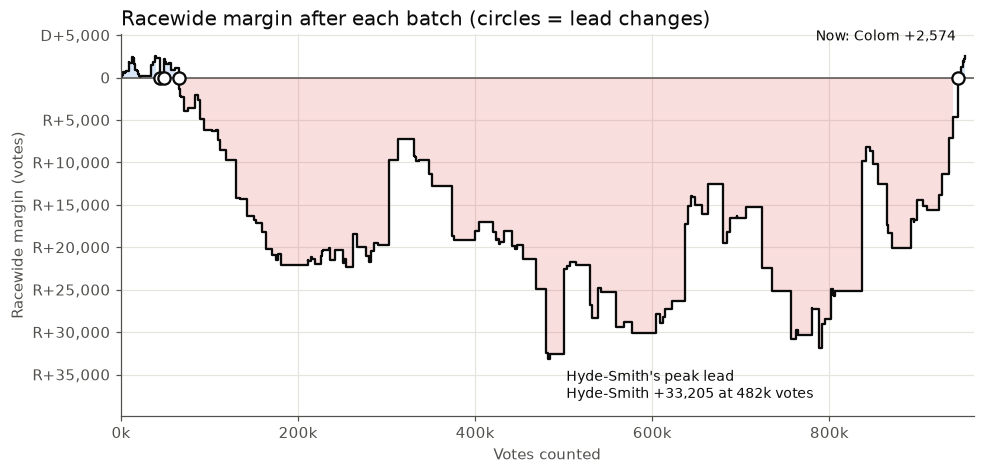

,batch,last_updated,cumulative_votes,new_votes,batch_margin,racewide_margin,est_pct_in
23,24,Nov. 3,43640,4699,-2841,-596,4.0
25,26,Nov. 3,48554,3175,2195,2176,5.0
32,33,Nov. 3,65393,4455,-2530,-1373,7.0
179,180,69h ago,945464,6373,4625,28,96.0


In [3]:
x = batches["cumulative_votes"]
y = batches["racewide_margin"]

# Lead changes: batches where the leader flips (ties are skipped, not counted as a flip).
leader = np.sign(y).replace(0, np.nan).ffill()
lead_changes = batches[leader.ne(leader.shift()) & leader.shift().notna()]
gop_peak = batches.loc[y.idxmin()]

fig, ax = plt.subplots()
ax.fill_between(x, y, 0, where=y >= 0, step="post", color=DEM_COLOR, alpha=0.18, linewidth=0)
ax.fill_between(x, y, 0, where=y <= 0, step="post", color=GOP_COLOR, alpha=0.18, linewidth=0)
ax.step(x, y, where="post", color=INK, linewidth=1.5)
ax.axhline(0, color=MUTED, linewidth=1)

ax.annotate(f"Hyde-Smith's peak lead\n{fmt_margin(gop_peak['racewide_margin'])} at {gop_peak['cumulative_votes'] / 1000:,.0f}k votes",
            (gop_peak["cumulative_votes"], gop_peak["racewide_margin"]), xytext=(12, -6),
            textcoords="offset points", va="top", color=INK, fontsize=9)
ax.annotate(f"Now: {fmt_margin(last['racewide_margin'])}", (last["cumulative_votes"], last["racewide_margin"]),
            xytext=(-6, 10), textcoords="offset points", ha="right", color=INK, fontsize=9)
for _, row in lead_changes.iterrows():
    ax.plot(row["cumulative_votes"], 0, "o", ms=8, mfc="white", mec=INK, mew=1.5, zorder=3)

ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(signed_votes)
ax.set_xlabel("Votes counted")
ax.set_ylabel("Racewide margin (votes)")
ax.set_title("Racewide margin after each batch (circles = lead changes)")
ax.set_xlim(0, x.max() * 1.01)
ax.set_ylim(y.min() * 1.2, y.max() + 2500)
plt.show()

lead_changes[["batch", "last_updated", "cumulative_votes", "new_votes", "batch_margin", "racewide_margin", "est_pct_in"]]

## 3. Every batch: size and lean

Each bar is one batch: its **width is the number of votes** and its **height is the batch's
margin**, so a bar's area is roughly the net votes it moved. Blue bars leaned Colom, red bars
Hyde-Smith. The dashed line is the current racewide margin.

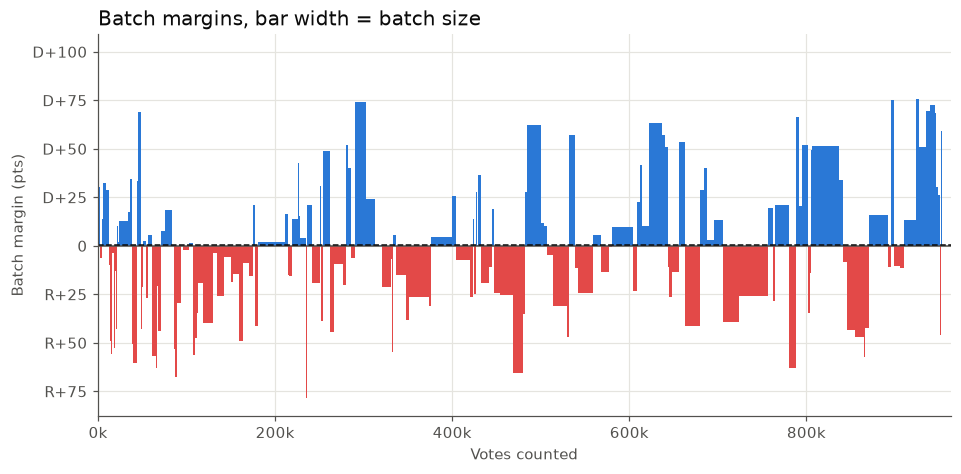

Largest batches:


,batch,last_updated,new_votes,dem_pct,gop_pct,batch_margin,racewide_margin
61,62,Nov. 3,30658,50.960598,49.039402,589,-21524
160,161,70h ago,29919,75.779605,24.220395,15426,-9781
93,94,Nov. 3,24322,52.331223,47.668777,1134,-18037
127,128,71h ago,22982,54.771125,45.228875,2193,-27901
91,92,Nov. 3,22392,36.805556,63.194444,-5909,-18648
148,149,71h ago,21957,37.106617,62.893383,-5662,-30866
168,169,70h ago,21284,57.933189,42.066811,3377,-16663
146,147,71h ago,18359,30.260363,69.739637,-7248,-22468


In [4]:
fig, ax = plt.subplots()
left = batches["cumulative_votes"] - batches["new_votes"]
colors = np.where(batches["batch_margin"] >= 0, DEM_COLOR, GOP_COLOR)
ax.bar(left, batches["batch_margin_pct"], width=batches["new_votes"], align="edge",
       color=colors, linewidth=0)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axhline(last["racewide_margin_pct"], color=INK, linewidth=1, linestyle="--")

ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(signed_pct)
ax.set_xlabel("Votes counted")
ax.set_ylabel("Batch margin (pts)")
ax.set_title("Batch margins, bar width = batch size")
ax.set_xlim(0, batches["cumulative_votes"].max() * 1.01)
plt.show()

print("Largest batches:")
batches.nlargest(8, "new_votes")[["batch", "last_updated", "new_votes", "dem_pct", "gop_pct", "batch_margin", "racewide_margin"]]

## 4. Count by day

The 121 election-night batches only say "Nov. 3"; the rest get a day from their approximate
time (PST).

In [5]:
batches["day"] = batches["approx_time_pst"].dt.date.fillna(pd.Timestamp("2026-11-03").date())

by_day = batches.groupby("day").agg(
    batches=("batch", "size"),
    votes=("new_votes", "sum"),
    dem_votes=("dem_votes", "sum"),
    gop_votes=("gop_votes", "sum"),
    net_margin=("batch_margin", "sum"),
    end_margin=("racewide_margin", "last"),
    end_pct_in=("est_pct_in", "last"),
)
by_day["margin_pct"] = 100 * by_day["net_margin"] / by_day["votes"]
by_day["share_of_all_votes"] = 100 * by_day["votes"] / by_day["votes"].sum()
by_day.round(2)

,batches,votes,dem_votes,gop_votes,net_margin,end_margin,end_pct_in,margin_pct,share_of_all_votes
day,,,,,,,,,
2026-11-03,180,945464,472746.0,472718.0,28,28,96.0,0.00,99.18
2026-11-04,5,3184,2147.0,1037.0,1110,1138,96.0,34.86,0.33
2026-11-05,10,3096,1885.5,1210.5,675,1813,97.0,21.80,0.32
2026-11-06,9,1570,1165.5,404.5,761,2574,97.0,48.47,0.16


## 5. What's left, and can Hyde-Smith catch up?

The outlet estimates 97% in. That figure is rounded and is itself a model of turnout, so we
try a range of "true % in now" values. For each, the remaining votes are
`counted / pct_in - counted`, and Hyde-Smith would need to win them by
`Colom's lead / remaining votes`. Compare that with how the late count (after election
night) has actually leaned.

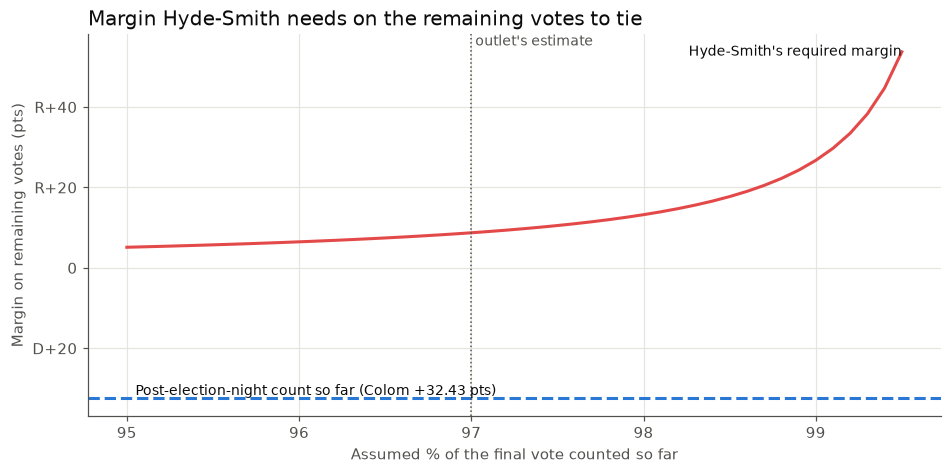

96.5% in: ~34,576 votes left; Hyde-Smith needs R+7.4 on them
97.0% in: ~29,484 votes left; Hyde-Smith needs R+8.7 on them
97.5% in: ~24,444 votes left; Hyde-Smith needs R+10.5 on them
Late count so far: 7,850 votes at Colom +32.43 pts


In [6]:
PCT_IN_NOW = np.arange(95.0, 99.6, 0.1)  # assumed true % of the final vote counted so far

counted = last["cumulative_votes"]
lead = last["racewide_margin"]
remaining = counted / (PCT_IN_NOW / 100) - counted
needed_gop_margin = 100 * lead / remaining  # Hyde-Smith's required margin on the rest, in pts

late = batches[batches["day"] > pd.Timestamp("2026-11-03").date()]
late_margin_pct = 100 * late["batch_margin"].sum() / late["new_votes"].sum()

fig, ax = plt.subplots()
ax.plot(PCT_IN_NOW, needed_gop_margin, color=GOP_COLOR, linewidth=2)
ax.axhline(-late_margin_pct, color=DEM_COLOR, linewidth=2, linestyle="--")
ax.axvline(last["est_pct_in"], color=MUTED, linewidth=1, linestyle=":")
ax.text(PCT_IN_NOW[-1], needed_gop_margin[-1], "  Hyde-Smith's required margin",
        color=INK, fontsize=9, va="center", ha="right")
ax.text(95.05, -late_margin_pct, f"Post-election-night count so far ({fmt_margin(late_margin_pct, pct=True)})",
        color=INK, fontsize=9, va="bottom")
ax.text(last["est_pct_in"], ax.get_ylim()[1], " outlet's estimate", color=MUTED, fontsize=9, va="top")

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"R+{v:.0f}" if v > 0 else f"D+{-v:.0f}" if v < 0 else "0"))
ax.set_xlabel("Assumed % of the final vote counted so far")
ax.set_ylabel("Margin on remaining votes (pts)")
ax.set_title("Margin Hyde-Smith needs on the remaining votes to tie")
plt.show()

for pct in [96.5, 97.0, 97.5]:
    rem = counted / (pct / 100) - counted
    print(f"{pct:.1f}% in: ~{rem:,.0f} votes left; Hyde-Smith needs R+{100 * lead / rem:.1f} on them")
print(f"Late count so far: {late['new_votes'].sum():,.0f} votes at {fmt_margin(late_margin_pct, pct=True)}")

## 6. Counties: where is the outstanding vote?

County results pasted on 2026-11-07 (`ms-special-counties-20261107.txt`, parsed by
`ms_special_counties.py`). Each county reports its own "% in", which gives a bottom-up
estimate of the outstanding vote instead of the single statewide 97%.

- Most counties just say **">95%"**, which could mean anything from 95% to fully counted. We
  bracket it: **fewest outstanding** treats ">95%" as 100%; **most outstanding** treats it as
  exactly 95%. Counties with a plain number (Hinds 93%, Lee 90%, ...) are the same in both.
- **Projected net** assumes each county's outstanding votes split like its votes so far. The
  late count has run far bluer than that (section 4), so this probably understates Colom.
- County margins are rounded, so the county total doesn't exactly match the statewide margin.

In [7]:
from ms_special_counties import load_counties

COUNTIES_TXT = "ms-special-counties-20261107.txt"
counties = load_counties(COUNTIES_TXT)

county_net = (counties["votes"] * counties["margin_pct"] / 100).sum()
print(f"Counties: {len(counties)}, votes: {counties['votes'].sum():,} (batch table: {last['cumulative_votes']:,.0f})")
print(f"Net margin from rounded county margins: {fmt_margin(county_net)} (actual: {fmt_margin(last['racewide_margin'])})")

scenarios = pd.DataFrame({
    "outstanding": [counties["outstanding_low"].sum(), counties["outstanding_high"].sum()],
    "projected_colom_net": [counties["projected_net_low"].sum(), counties["projected_net_high"].sum()],
}, index=["fewest outstanding ('>95%' = 100%)", "most outstanding ('>95%' = 95%)"])
scenarios["projected_final_margin"] = last["racewide_margin"] + scenarios["projected_colom_net"]
scenarios["hyde_smith_needs_pts"] = 100 * last["racewide_margin"] / scenarios["outstanding"]
scenarios.round(1)

Counties: 82, votes: 953,314 (batch table: 953,314)
Net margin from rounded county margins: Colom +1,976 (actual: Colom +2,574)


,outstanding,projected_colom_net,projected_final_margin,hyde_smith_needs_pts
fewest outstanding ('>95%' = 100%),12081.0,4081.7,6655.7,21.3
most outstanding ('>95%' = 95%),53965.2,1282.6,3856.6,4.8


The counties with the most votes still to count, under the **most outstanding** reading. Bars
show the net votes each county's outstanding ballots would add if they split like the county
so far; labels give the county's reported % in.

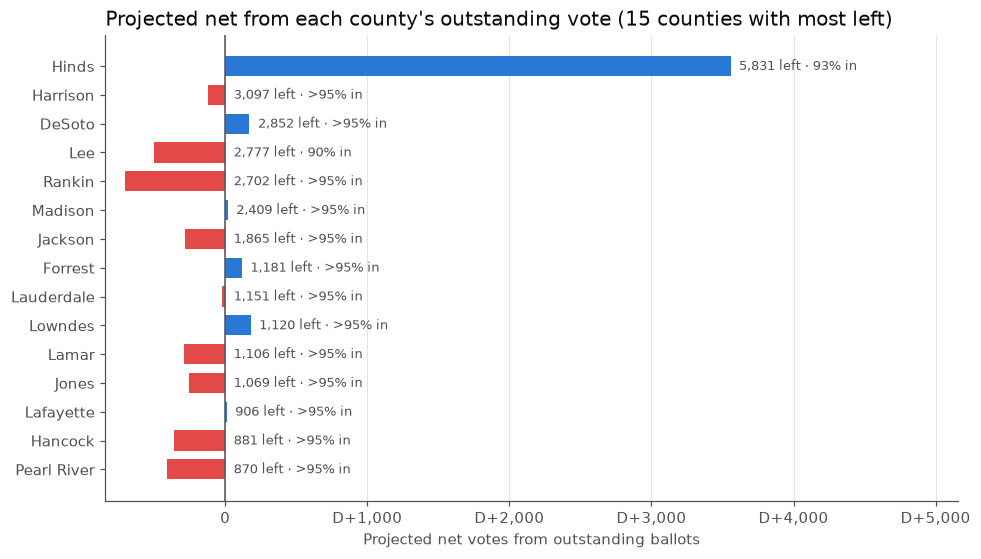

,county,margin_pct,votes,pct_in,outstanding_low,outstanding_high,projected_net_high
0,Hinds,61.0,77465,93%,5831.0,5831.0,3557.0
1,Harrison,-4.0,58850,>95%,0.0,3097.0,-124.0
2,DeSoto,6.0,54184,>95%,0.0,2852.0,171.0
6,Lee,-18.0,24993,90%,2777.0,2777.0,-500.0
3,Rankin,-26.0,51331,>95%,0.0,2702.0,-702.0
4,Madison,1.0,45766,>95%,0.0,2409.0,18.0
5,Jackson,-15.0,35432,>95%,0.0,1865.0,-280.0
7,Forrest,10.0,22433,>95%,0.0,1181.0,118.0
8,Lauderdale,-2.0,21874,>95%,0.0,1151.0,-20.0
9,Lowndes,16.0,21284,>95%,0.0,1120.0,179.0


In [8]:
top = counties.nlargest(15, "outstanding_high").iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = np.where(top["projected_net_high"] >= 0, DEM_COLOR, GOP_COLOR)
ax.barh(top["county"], top["projected_net_high"], color=colors, height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
for _, row in top.iterrows():
    net = row["projected_net_high"]
    ax.text(max(net, 0) + 60, row["county"], f"{row['outstanding_high']:,.0f} left · {row['pct_in']} in",
            va="center", ha="left", color=MUTED, fontsize=8.5)

ax.xaxis.set_major_formatter(signed_votes)
ax.set_xlim(top["projected_net_high"].min() * 1.2, top["projected_net_high"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Projected net votes from outstanding ballots")
ax.set_title("Projected net from each county's outstanding vote (15 counties with most left)")
plt.show()

counties.nlargest(15, "outstanding_high")[["county", "margin_pct", "votes", "pct_in", "outstanding_low", "outstanding_high", "projected_net_high"]].round(0)

**Reading it:** the outstanding vote isn't spread evenly. Hinds, the bluest big county
(Colom +61), is also the furthest from done at 93%, so it alone projects to roughly +3,500
Colom. Even in the most-outstanding case, where every ">95%" county still has 5% left and those
include the red suburbs (Rankin, Harrison, Jackson), the projection still adds to Colom's lead.
For Hyde-Smith to win, the remaining ballots would have to be far redder than their own
counties, the opposite of what the late count has done so far.